In [ ]:
# import packages
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [ ]:
# set filepaths
DATA_DIR = Path("Data/")

# define ERA5 lat & lon 
lat = np.arange(90.0, -90.0-0.01, -0.25)
lon = np.arange(-180, 180, 0.25)

#### load metrics of data biases from 1980-2025

In [ ]:
with h5py.File(DATA_DIR/"bias_metric_tmax.h5", "r") as fmax:
    me_tmax = fmax["mean_bias"][:]
    std_tmax = fmax["std_krig"][:]
    rmse_tmax = fmax["rmse"][:]
    crmse_tmax = fmax["crmse"][:]
    count_tmax = fmax["count_days"][:]
    exhi_tmax = fmax["exceed_high"][:]
    exlo_tmax = fmax["exceed_low"][:]
    
with h5py.File(DATA_DIR/"bias_metric_tmin.h5", "r") as fmin:
    me_tmin = fmin["mean_bias"][:]
    std_tmin = fmin["std_krig"][:]
    rmse_tmin = fmin["rmse"][:]
    crmse_tmin = fmin["crmse"][:]
    count_tmin = fmin["count_days"][:]
    exhi_tmin = fmin["exceed_high"][:]
    exlo_tmin = fmin["exceed_low"][:]

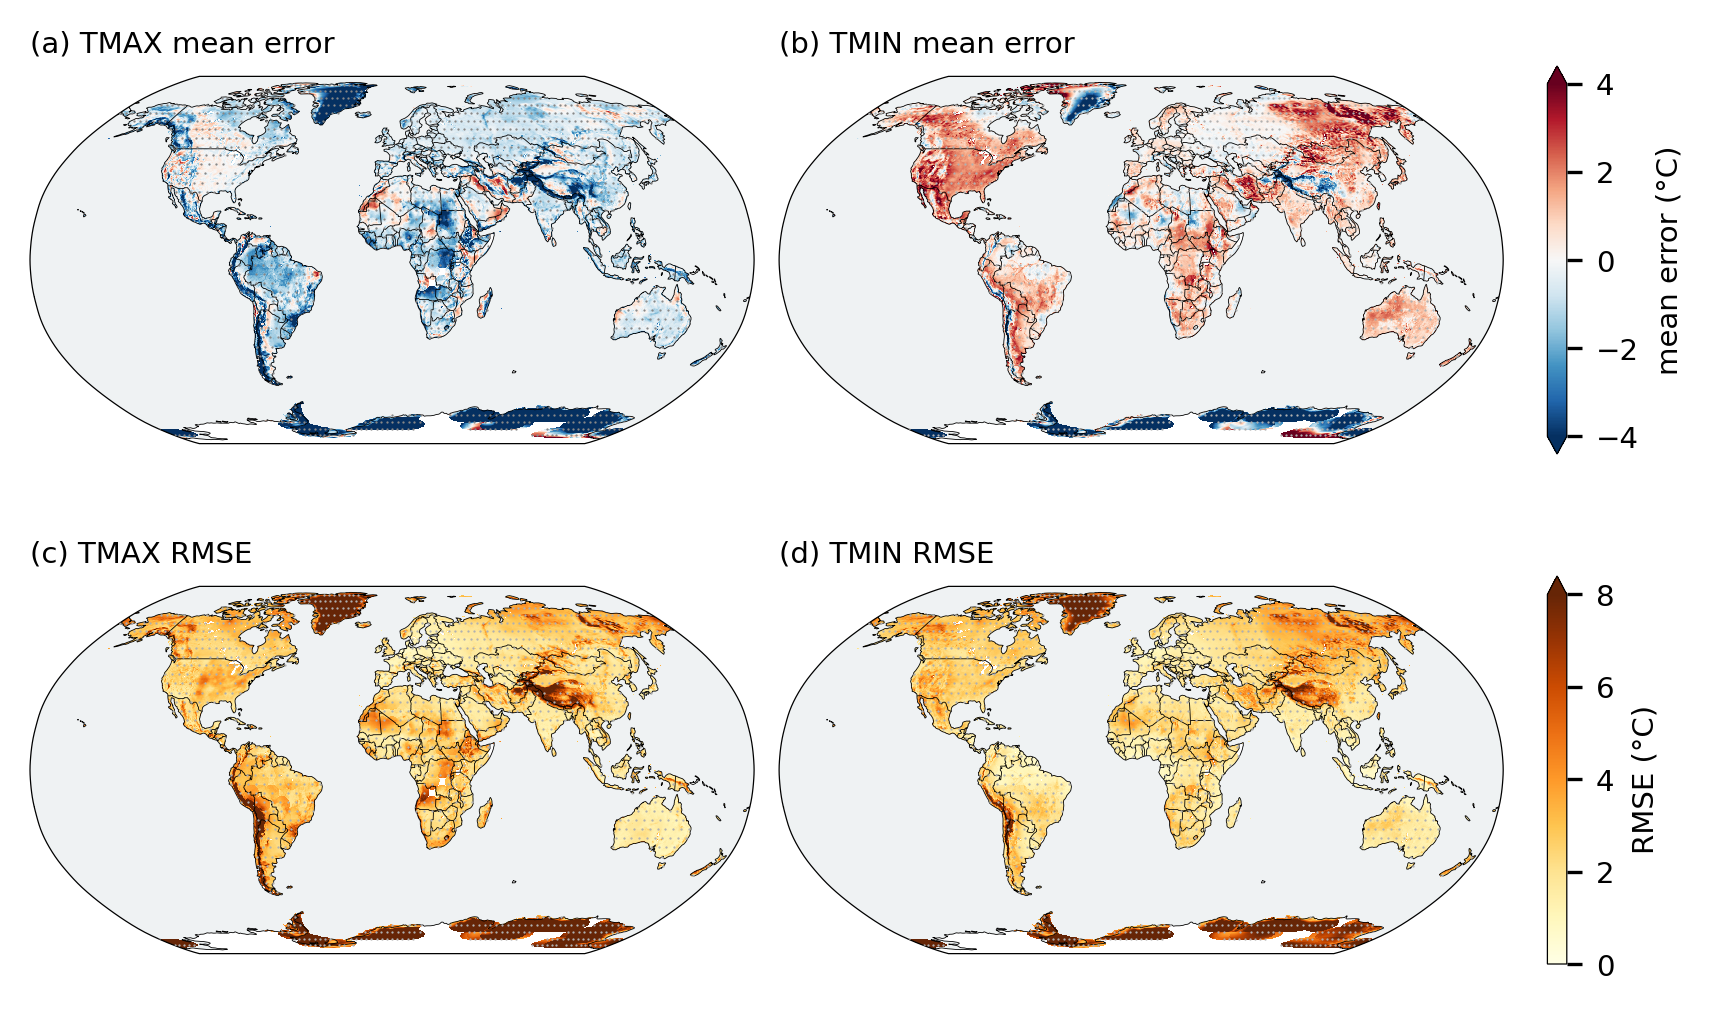

In [ ]:
# ===== plot mean bias ===== #
# create lon/lat meshgrid
LON, LAT = np.meshgrid(lon, lat)
proj = ccrs.PlateCarree()

# apply signifiance mask
sig_TMAX = ( (me_tmax - 1.96*std_tmax) > 0 ) | ( (me_tmax + 1.96*std_tmax) < 0)
sig_TMIN = ((me_tmin - 1.96*std_tmin) > 0) | ((me_tmin + 1.96*std_tmin) < 0)

# obtain the significance mask w. reduced density for visuallization
stride = 16
sig_sparse_TMAX = np.zeros_like(sig_TMAX)
sig_sparse_TMAX[::stride, ::stride] = sig_TMAX[::stride, ::stride]
sig_lon_TMAX = LON[sig_sparse_TMAX]
sig_lat_TMAX = LAT[sig_sparse_TMAX]

sig_sparse_TMIN = np.zeros_like(sig_TMIN)
sig_sparse_TMIN[::stride, ::stride] = sig_TMIN[::stride, ::stride]
sig_lon_TMIN = LON[sig_sparse_TMIN]
sig_lat_TMIN = LAT[sig_sparse_TMIN]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(5.6, 3.4), dpi=300, 
                         constrained_layout=True, subplot_kw={'projection': ccrs.Robinson()})

ocean =  cfeature.OCEAN.with_scale("110m")

# subpanel (a)
axes[0,0].add_feature(
    ocean,
    facecolor="#ECEFF1",
    edgecolor="none",
    alpha=0.8,
    zorder=0
)
for spine in axes[0,0].spines.values():
    spine.set_linewidth(0.3)
axes[0,0].set_title("(a) TMAX mean error", loc='left', fontsize=7)
im1 = axes[0,0].pcolormesh(LON, LAT, me_tmax, cmap='RdBu_r', shading='auto', vmin=-4, vmax=4, transform=proj)
# add significance level
axes[0,0].scatter(sig_lon_TMAX, sig_lat_TMAX, s=0.3, c='#888888', marker='o', linewidth=0, alpha=1, transform=ccrs.PlateCarree(), zorder=5)
axes[0,0].coastlines(linewidth=0.2)
axes[0,0].add_feature(cfeature.BORDERS, linewidth=0.2)

# subpanel (b)
axes[0,1].add_feature(
    ocean,
    facecolor="#ECEFF1",
    edgecolor="none",
    alpha=0.8,
    zorder=0
)
for spine in axes[0,1].spines.values():
    spine.set_linewidth(0.3)
axes[0,1].set_title("(b) TMIN mean error", loc='left', fontsize=7)
im2 = axes[0,1].pcolormesh(LON, LAT, me_tmin, cmap='RdBu_r', shading='auto', vmin=-4, vmax=4, transform=proj)
# add significance level
axes[0,1].scatter(sig_lon_TMIN, sig_lat_TMIN, s=0.3, c='#B0B0B0', marker='o', linewidth=0, alpha=1, transform=ccrs.PlateCarree(), zorder=5)
axes[0,1].coastlines(linewidth=0.2)
axes[0,1].add_feature(cfeature.BORDERS, linewidth=0.2)
cbar2 = plt.colorbar(im2, ax=axes[0,:], fraction=0.02, shrink=0.8, extend='both', pad=0.03, ticks=np.arange(-4, 4+1, 2), orientation="vertical")
cbar2.ax.tick_params(labelsize=7)
cbar2.set_label('mean error (°C)', fontsize=7)
cbar2.outline.set_linewidth(0.3)

# subpanel (c)
axes[1,0].add_feature(
    ocean,
    facecolor="#ECEFF1",
    edgecolor="none",
    alpha=0.8,
    zorder=0
)
for spine in axes[1,0].spines.values():
    spine.set_linewidth(0.3)
axes[1,0].set_title("(c) TMAX RMSE", loc='left', fontsize=7)
im3 = axes[1,0].pcolormesh(LON, LAT, rmse_tmax, cmap='YlOrBr', shading='auto', vmin=0, vmax=8, transform=proj)
# add significance level
axes[1,0].scatter(sig_lon_TMAX, sig_lat_TMAX, s=0.3, c='#B0B0B0', marker='o', linewidth=0, alpha=1, transform=ccrs.PlateCarree(), zorder=5)
axes[1,0].coastlines(linewidth=0.2)
axes[1,0].add_feature(cfeature.BORDERS, linewidth=0.2)

# subpanel (d)
axes[1,1].add_feature(
    ocean,
    facecolor="#ECEFF1",
    edgecolor="none",
    alpha=0.8,
    zorder=0
)
for spine in axes[1,1].spines.values():
    spine.set_linewidth(0.3)
axes[1,1].set_title("(d) TMIN RMSE", loc='left', fontsize=7)
im4 = axes[1,1].pcolormesh(LON, LAT, rmse_tmin, cmap='YlOrBr', shading='auto', vmin=0, vmax=8, transform=proj)
# add significance level
axes[1,1].scatter(sig_lon_TMIN, sig_lat_TMIN, s=0.3, c='#B0B0B0', marker='o', linewidth=0, alpha=1, transform=ccrs.PlateCarree(), zorder=5)
axes[1,1].coastlines(linewidth=0.2)
axes[1,1].add_feature(cfeature.BORDERS, linewidth=0.2)
cbar4 = plt.colorbar(im4, ax=axes[1,:], fraction=0.02, shrink=0.8, extend='max', pad=0.03, ticks=np.arange(0, 8+1, 2), orientation="vertical")
cbar4.ax.tick_params(labelsize=7)
cbar4.set_label('RMSE (°C)', fontsize=7)
cbar4.outline.set_linewidth(0.3)
